# 1 · Datos del CFPB, partición temporal y deriva

Los textos originales están **en inglés** (narrativas reales del CFPB, con máscaras `XXXX` de privacidad). La partición es temporal: se entrena con quejas antiguas y se prueba con recientes.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, Markdown, display

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ))
from quejas import config
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)
R = json.loads((config.REPORTES / "resultados.json").read_text(encoding="utf-8"))
fig = lambda nombre: display(Image(filename=str(config.FIGURAS / nombre)))

## 1.1 · Particiones y mapeo producto CFPB → mesa (agrupación propia)

,categoria,test,test_misma_epoca,train,val
0,reporte_credito,4747,663,5481,5066
1,cobranza_deudas,2436,805,6955,2339
2,hipotecas,781,503,4324,886
3,tarjetas_credito,995,343,3131,936
4,cuentas_bancarias,969,298,2417,739
5,prestamos_consumo,842,388,3414,1110


,producto_cfpb,mesa
0,Debt collection,cobranza_deudas
1,Checking or savings account,cuentas_bancarias
2,Bank account or service,cuentas_bancarias
3,"Money transfer, virtual currency, or money ser...",cuentas_bancarias
4,Money transfers,cuentas_bancarias
5,Mortgage,hipotecas
6,Student loan,prestamos_consumo
7,Vehicle loan or lease,prestamos_consumo
8,Consumer Loan,prestamos_consumo
9,"Payday loan, title loan, or personal loan",prestamos_consumo


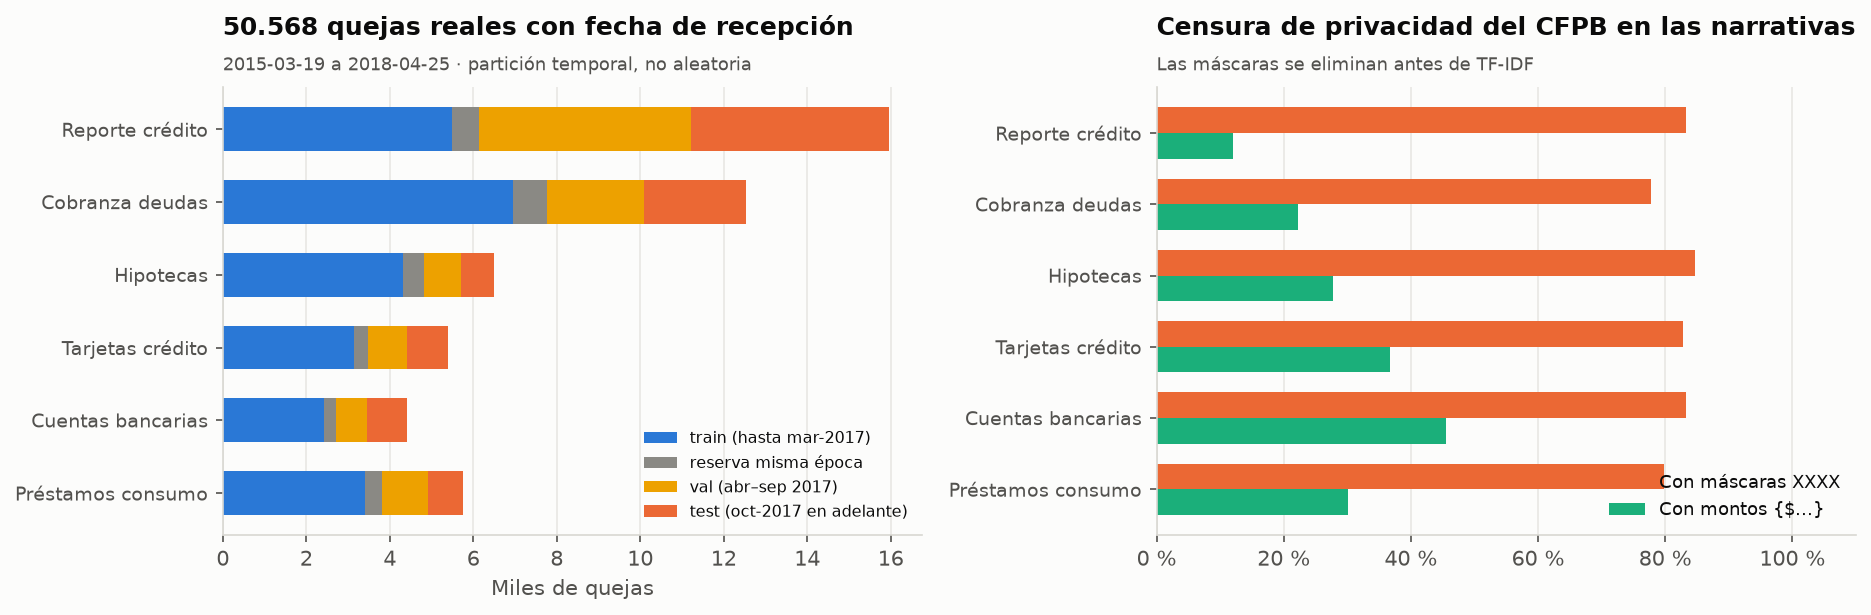

In [2]:
display(pd.read_csv(config.REPORTES / "particiones_temporales.csv"))
import descargar_datos as dd
display(pd.DataFrame(sorted(dd.MAPEO_PRODUCTO.items(), key=lambda x: x[1]), columns=["producto_cfpb", "mesa"]))
fig("01_datos_y_particiones_temporales.png")

## 1.2 · Ejemplo de limpieza de máscaras `XXXX`

In [3]:
from quejas import datos
df = datos.cargar_corpus_cfpb()
q = df[df["orden_comun"] == 0].iloc[0]
print(q["fecha_recepcion"].date(), "|", q["producto_original"], "->", q["categoria"])
print("\nOriginal:\n", q["texto_queja"][:400])
print("\nPara TF-IDF:\n", q["texto_limpio_tfidf"][:400])
print("\nPara bge-m3 / LLM:\n", q["texto_corto"][:400])

2017-12-20 | Credit reporting, credit repair services, or other personal consumer reports -> reporte_credito

Original:
 I was at a auto dealer on behalf of my brother as a cosigner. I ask the Salesperson to do not inquire my credit by more than XXXX XXXX XXXX ( creditor ). He agreed but I have three inquires on my credit report - XXXX XXXX, XXXX. In XXXX of XXXX I called the salesman ( XXXX ) and asked why he did not follow our agreement and he 's response was that it was not him, it was his manager.

Para TF-IDF:
 I was at a auto dealer on behalf of my brother as a cosigner. I ask the Salesperson to do not inquire my credit by more than ( creditor ). He agreed but I have three inquires on my credit report - , . In of I called the salesman ( ) and asked why he did not follow our agreement and he 's response was that it was not him, it was his manager.

Para bge-m3 / LLM:
 I was at a auto dealer on behalf of my brother as a cosigner. I ask the Salesperson to do not inquire my credit by

## 1.3 · Deriva temporal (TF-IDF + LR entrenado hasta marzo de 2017)

,conjunto,n_quejas,f1_macro,f1_ic95_bajo,f1_ic95_alto,exactitud
0,"misma época que train (2015–T1 2017, reserva a...",3000,0.846,0.832,0.859,0.856
1,recientes (T4 2017 – 2018),10770,0.774,0.765,0.783,0.784


IC 95 % de la diferencia (recientes − misma época): [-0.087, -0.056]


,trimestre,n_quejas,f1_macro,exactitud
0,2017Q2,4866,0.806,0.811
1,2017Q3,6210,0.793,0.816
2,2017Q4,5206,0.774,0.783
3,2018Q1,5054,0.778,0.786
4,2018Q2,510,0.731,0.773


,categoria,f1_misma_epoca,f1_recientes
0,reporte_credito,0.880,0.807
1,cobranza_deudas,0.864,0.791
2,hipotecas,0.918,0.858
3,tarjetas_credito,0.788,0.700
4,cuentas_bancarias,0.815,0.822
5,prestamos_consumo,0.812,0.668


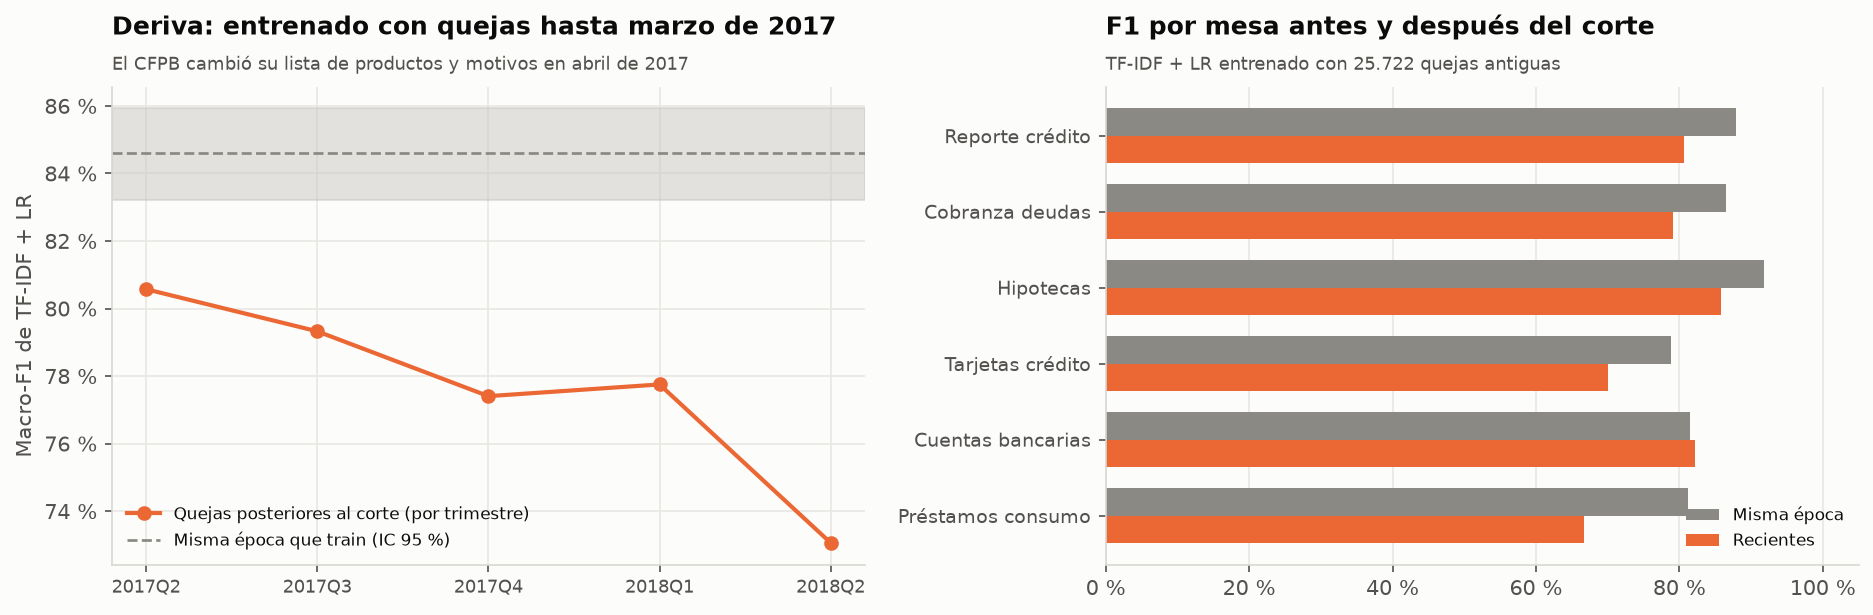

In [4]:
display(pd.read_csv(config.REPORTES / "deriva_temporal.csv"))
print("IC 95 % de la diferencia (recientes − misma época):", [round(x, 3) for x in R["deriva_diferencia_ic95"]])
display(pd.read_csv(config.REPORTES / "deriva_por_trimestre.csv"))
display(pd.read_csv(config.REPORTES / "deriva_f1_por_mesa.csv"))
fig("04_deriva_temporal.png")